# Black Sea 2 km dataset: EDA

Copernicus Marine Black Sea products arranged by `scripts/fetch_cmems.py` into `~/mind_the_chl_gap/data/cmems/blk_2km/<year>.zarr`:
CHL L3 (1 km, multi-sensor, `cmems_obs-oc_blk_bgc-plankton_my_l3-multi-1km_P1D`) and gap-free L4 (same grid, DINEOF-based), block-averaged 2×2 in log space
(`chl_l3`, `chl_l3_n` = valid 1 km pixels per block, `chl_l4`, `qi_chl`), and the Black Sea physics reanalysis surface layer (2.5 km, `BLKSEA_MULTIYEAR_PHY_007_004`)
interpolated onto that grid: `thetao`, `so`, `uo`, `vo`, `mlotst`, `zos`, `tauuo`, `tauvo`. Daily, 1998-01-01 to 2024-12-31.

Conventions: ln CHL throughout; "observed" = L3 finite on an ocean pixel; "real cloud" = ocean pixel with no L3 value (also includes glint, aerosol, swath gaps).
Maps and heavy statistics use every 10th day unless stated (memory: a training job shares the machine). The L4 is an interpolation product and is treated as a reference field, not truth.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
from fetch_cmems import open_arranged
from chl_cnn.plotting import OKABE_ITO, MAP_CMAP, ERR_CMAP
from chl_cnn.physics import grid_metrics

d = open_arranged("blk", 2)
t = pd.to_datetime(d.time.values)
lat, lon = d.lat.values, d.lon.values
ocean = d.ocean.values
ext = [lon[0], lon[-1], lat[0], lat[-1]]  # lat ascends in this store -> origin='lower'
print(
    dict(d.sizes),
    "| ocean px",
    int(ocean.sum()),
    f"({ocean.mean():.1%} of grid) |",
    t[0].date(),
    "->",
    t[-1].date(),
    "| grid step",
    round(abs(float(lat[1] - lat[0])), 4),
    "°",
)
sub = slice(0, None, 10)
chl3 = np.log(d.chl_l3.isel(time=sub).values)
chl4 = np.log(d.chl_l4.isel(time=sub).values)
ts = t[sub]
obs = np.isfinite(chl3) & ocean
cloud = ocean & ~obs
print(
    f"loaded every 10th day: {len(ts)} days; observed fraction of ocean pixel-days {obs[:, ocean].mean():.3f}"
)

{'time': 9862, 'lat': 395, 'lon': 550} | ocean px 93594 (43.1% of grid) | 1998-01-01 -> 2024-12-31 | grid step 0.0203 °


loaded every 10th day: 987 days; observed fraction of ocean pixel-days 0.386


## 1. Data availability

Observed (L3) fraction of ocean pixels per day, by month, and per pixel; physics coverage.

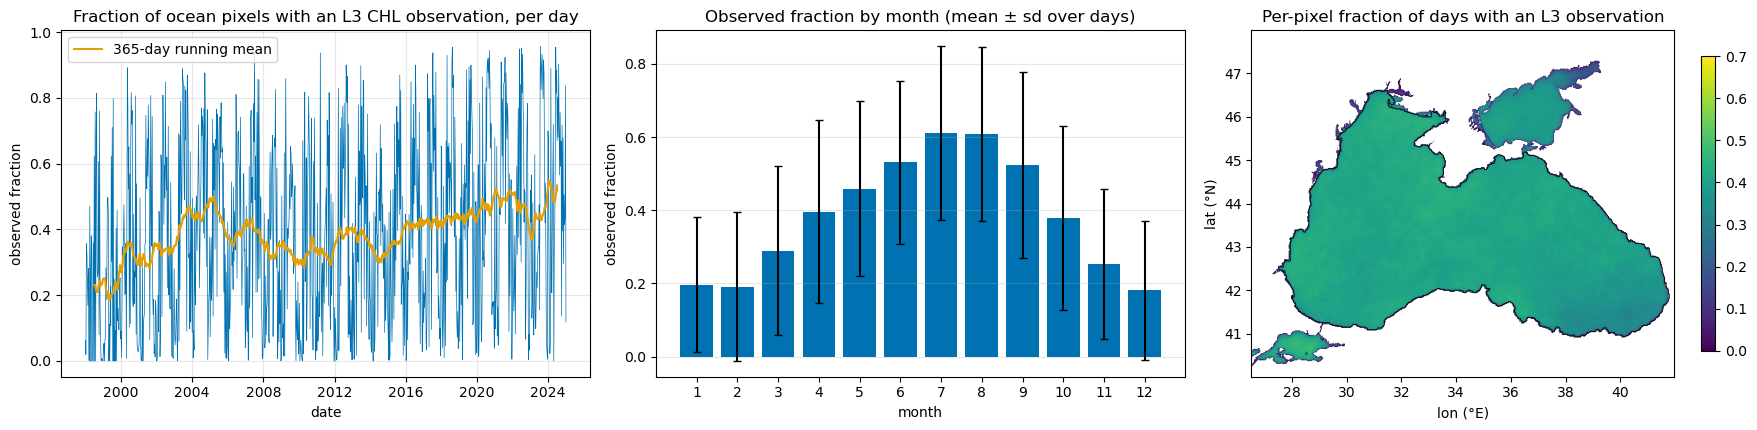

physics (reanalysis) covers 85.5% of CHL ocean pixels (black contour); outside it the physics channels are NaN (Azov, Marmara, some coast)


In [2]:
obs_frac = obs[:, ocean].mean(1)
phys = np.isfinite(d.thetao.isel(time=0).values) & ocean
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
ax[0].plot(ts, obs_frac, lw=0.5, color=OKABE_ITO[0])
ax[0].plot(
    pd.Series(obs_frac, ts).rolling(37, center=True).mean(),
    color=OKABE_ITO[1],
    label="365-day running mean",
)
ax[0].set(
    title="Fraction of ocean pixels with an L3 CHL observation, per day",
    xlabel="date",
    ylabel="observed fraction",
)
ax[0].legend()
ax[0].grid(alpha=0.3)
m = pd.Series(obs_frac, ts).groupby(ts.month).agg(["mean", "std"])
ax[1].bar(m.index, m["mean"], yerr=m["std"], color=OKABE_ITO[0], capsize=3)
ax[1].set(
    title="Observed fraction by month (mean ± sd over days)",
    xlabel="month",
    ylabel="observed fraction",
    xticks=range(1, 13),
)
ax[1].grid(alpha=0.3, axis="y")
pf = obs.mean(0).astype(float)
pf[~ocean] = np.nan
im = ax[2].imshow(
    pf, extent=ext, origin="lower", cmap="viridis", vmin=0, vmax=0.7, aspect="auto"
)
ax[2].set(
    title="Per-pixel fraction of days with an L3 observation",
    xlabel="lon (°E)",
    ylabel="lat (°N)",
)
fig.colorbar(im, ax=ax[2], shrink=0.85)
ax[2].contour(lon, lat, phys.astype(float), levels=[0.5], colors="k", linewidths=0.6)
fig.tight_layout()
plt.show()
print(
    f"physics (reanalysis) covers {phys[ocean].mean():.1%} of CHL ocean pixels (black contour); outside it the physics channels are NaN (Azov, Marmara, some coast)"
)

## 2. Climatology of ln CHL

Seasonal means over observed pixels (clear-sky climatology; see the clear-sky-bias caveat in `docs/archive/claudes_summary.md` §2.2).

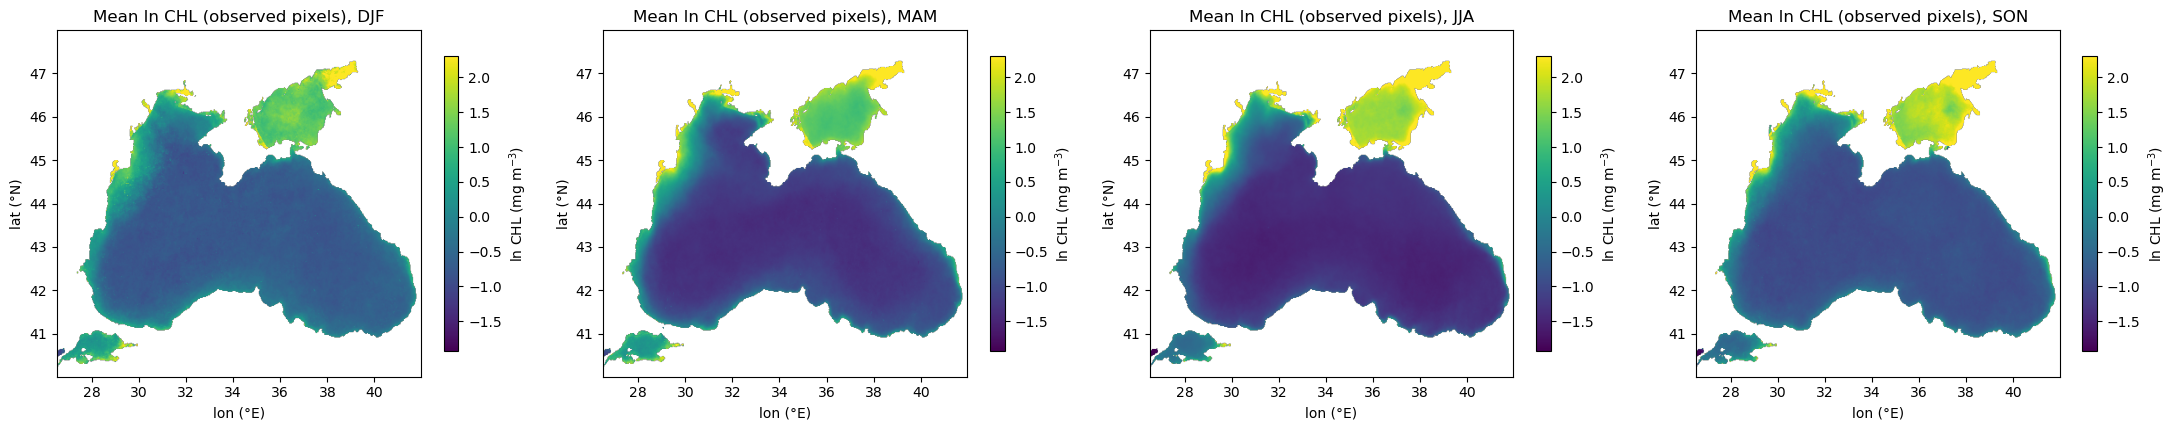

ln CHL on observed ocean pixels: percentiles 1/50/99 = [-2.01 -0.98  2.85]  (mg/m3: [ 0.13  0.37 17.24] )


In [3]:
seasons = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}
fig, ax = plt.subplots(1, 4, figsize=(22, 4.4))
allv = chl3[obs]
vmin, vmax = np.percentile(allv, 2), np.percentile(allv, 98)
for k, (nm, mo) in enumerate(seasons.items()):
    s = np.isin(ts.month, mo)
    c = np.nanmean(np.where(obs[s], chl3[s], np.nan), 0)
    c[~ocean] = np.nan
    im = ax[k].imshow(
        c,
        extent=ext,
        origin="lower",
        cmap=MAP_CMAP,
        vmin=vmin,
        vmax=vmax,
        aspect="auto",
    )
    ax[k].set(
        title=f"Mean ln CHL (observed pixels), {nm}",
        xlabel="lon (°E)",
        ylabel="lat (°N)",
    )
    fig.colorbar(im, ax=ax[k], label="ln CHL (mg m$^{-3}$)", shrink=0.85)
fig.tight_layout()
plt.show()
print(
    "ln CHL on observed ocean pixels: percentiles 1/50/99 =",
    np.round(np.percentile(allv, [1, 50, 99]), 2),
    " (mg/m3:",
    np.round(np.exp(np.percentile(allv, [1, 50, 99])), 2),
    ")",
)

## 3. Time series of basin-box means

Monthly means over the interior (deep basin, >200 km from coast approximated by a lat/lon box), the NW shelf (Danube influence) and the whole basin; ln CHL on observed pixels, SST and mixed-layer depth from the reanalysis.

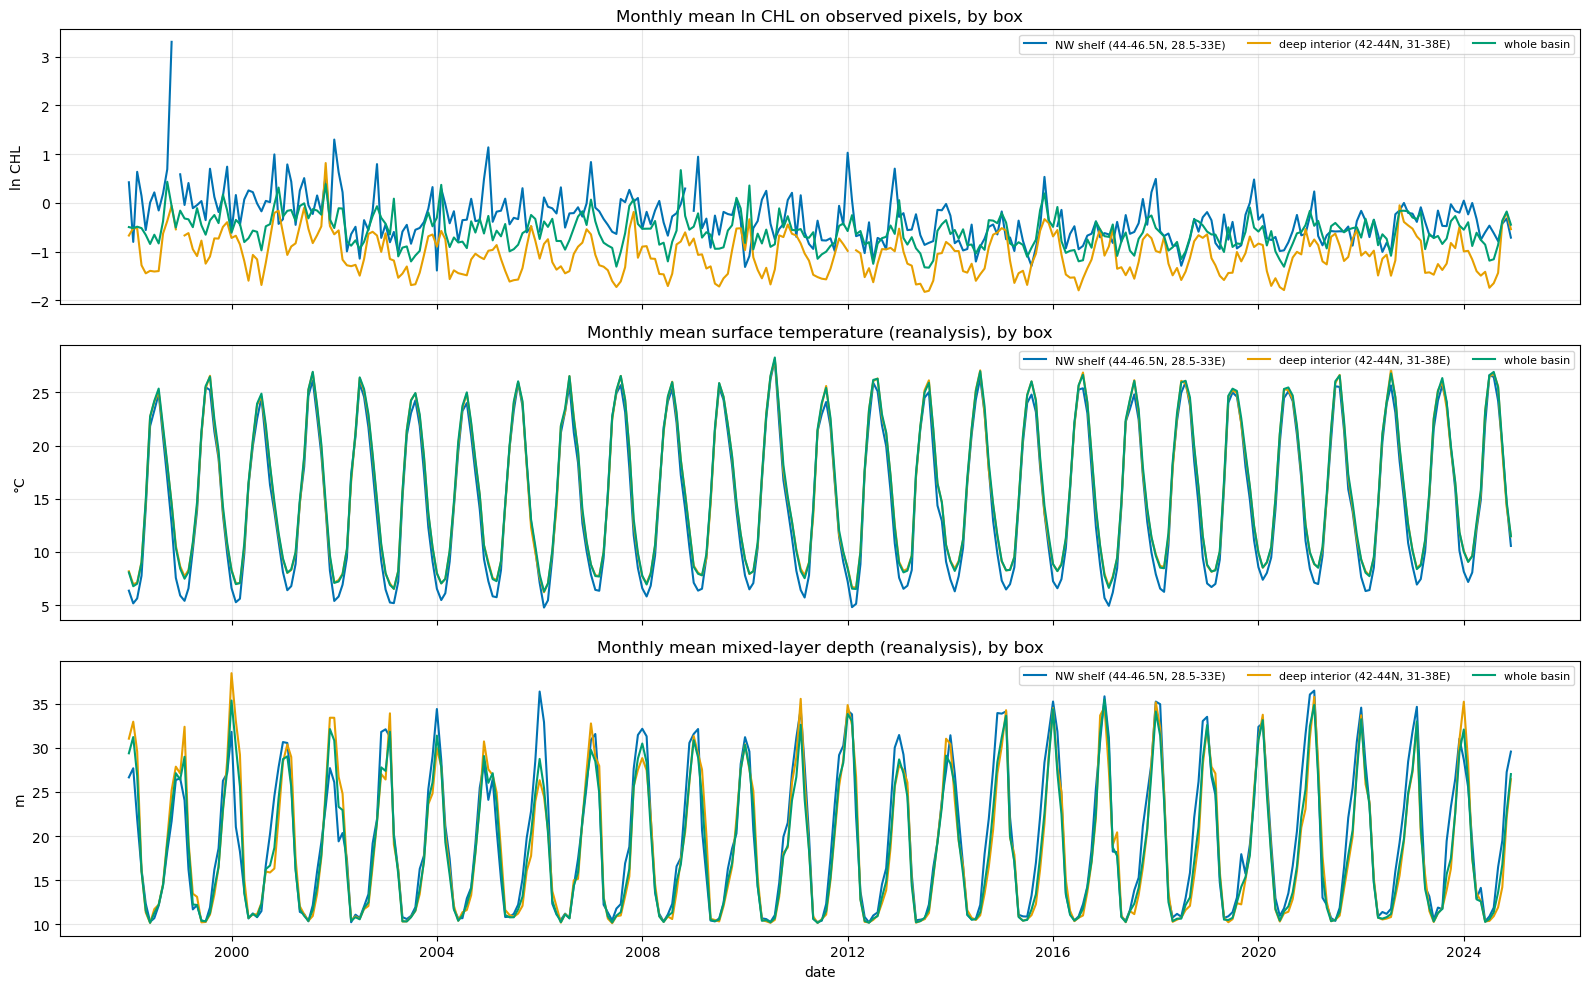

In [4]:
boxes = {
    "NW shelf (44-46.5N, 28.5-33E)": (44, 46.5, 28.5, 33),
    "deep interior (42-44N, 31-38E)": (42, 44, 31, 38),
    "whole basin": (40, 48, 26.5, 42),
}


def boxmask(la0, la1, lo0, lo1):
    return (
        ocean
        & (lat[:, None] >= la0)
        & (lat[:, None] <= la1)
        & (lon[None, :] >= lo0)
        & (lon[None, :] <= lo1)
    )


sst = d.thetao.isel(time=sub).values
mld = d.mlotst.isel(time=sub).values
fig, ax = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
for k, (nm, b) in enumerate(boxes.items()):
    bm = boxmask(*b)
    c = np.array(
        [
            np.nanmean(chl3[i][bm & obs[i]]) if (bm & obs[i]).sum() > 50 else np.nan
            for i in range(len(ts))
        ]
    )
    ax[0].plot(pd.Series(c, ts).resample("MS").mean(), color=OKABE_ITO[k], label=nm)
    ax[1].plot(
        pd.Series(np.nanmean(sst[:, bm], 1), ts).resample("MS").mean(),
        color=OKABE_ITO[k],
        label=nm,
    )
    ax[2].plot(
        pd.Series(np.nanmean(mld[:, bm], 1), ts).resample("MS").mean(),
        color=OKABE_ITO[k],
        label=nm,
    )
ax[0].set(title="Monthly mean ln CHL on observed pixels, by box", ylabel="ln CHL")
ax[1].set(title="Monthly mean surface temperature (reanalysis), by box", ylabel="°C")
ax[2].set(
    title="Monthly mean mixed-layer depth (reanalysis), by box",
    ylabel="m",
    xlabel="date",
)
for a in ax:
    a.grid(alpha=0.3)
    a.legend(fontsize=8, ncol=3)
fig.tight_layout()
plt.show()

## 4. L3 vs L4

Where L3 is observed, how close is the L4 to it (the L4 should reproduce observations there)? And what does the L4 look like under real clouds relative to the clear-sky climatology?

L4 − L3 on observed pixels: mean -0.0047, MAE 0.0206, 99th pct |diff| 0.430 ln CHL  (n = 35,628,733)


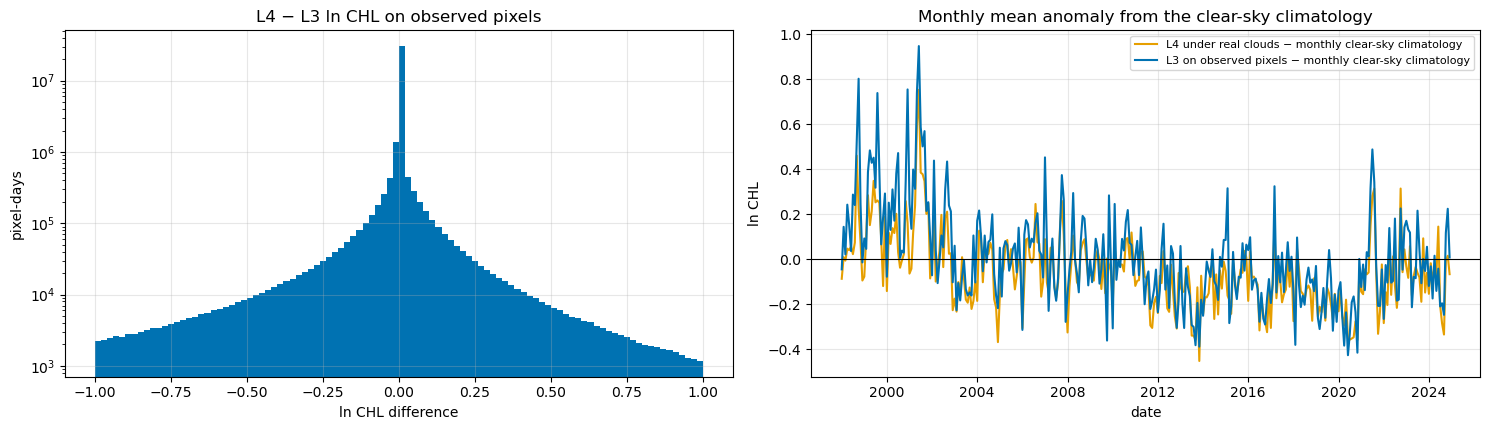

mean anomaly of L4 under real clouds: -0.058 ln CHL; of L3 on observed pixels: +0.002


In [5]:
dif = chl4 - chl3
m = obs & np.isfinite(chl4)
print(
    f"L4 − L3 on observed pixels: mean {np.nanmean(dif[m]):+.4f}, MAE {np.nanmean(np.abs(dif[m])):.4f}, 99th pct |diff| {np.nanpercentile(np.abs(dif[m]), 99):.3f} ln CHL  (n = {m.sum():,})"
)
clim = np.full((12,) + ocean.shape, np.nan)
for mo in range(1, 13):
    s = ts.month == mo
    clim[mo - 1] = np.nanmean(np.where(obs[s], chl3[s], np.nan), 0)
an4 = np.full(len(ts), np.nan)
an3 = np.full(len(ts), np.nan)
for i in range(len(ts)):
    c = clim[ts.month[i] - 1]
    cl = cloud[i] & np.isfinite(chl4[i]) & np.isfinite(c)
    ob_ = obs[i] & np.isfinite(c)
    an4[i] = np.nanmean(chl4[i][cl] - c[cl]) if cl.sum() > 100 else np.nan
    an3[i] = np.nanmean(chl3[i][ob_] - c[ob_]) if ob_.sum() > 100 else np.nan
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
ax[0].hist(dif[m], bins=np.linspace(-1, 1, 101), color=OKABE_ITO[0])
ax[0].set(
    title="L4 − L3 ln CHL on observed pixels",
    xlabel="ln CHL difference",
    ylabel="pixel-days",
    yscale="log",
)
ax[0].grid(alpha=0.3)
ax[1].plot(
    pd.Series(an4, ts).resample("MS").mean(),
    color=OKABE_ITO[1],
    label="L4 under real clouds − monthly clear-sky climatology",
)
ax[1].plot(
    pd.Series(an3, ts).resample("MS").mean(),
    color=OKABE_ITO[0],
    label="L3 on observed pixels − monthly clear-sky climatology",
)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(
    title="Monthly mean anomaly from the clear-sky climatology",
    xlabel="date",
    ylabel="ln CHL",
)
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()
print(
    f"mean anomaly of L4 under real clouds: {np.nanmean(an4):+.3f} ln CHL; of L3 on observed pixels: {np.nanmean(an3):+.3f}"
)

## 5. Day-to-day change and the Courant number at 2 km

Consecutive-day pairs (full daily record for one year per decade): |Δ ln CHL| on pixels observed both days, and the Courant number of the reanalysis currents on the 2 km grid (cells per day). At 0.25° the Indian Ocean median was 1.05; here the grid is 12× finer.

 year   px pairs  mean|Δ|  median    p90  Co median   Co>1   Co>5
 2000  5,459,288    0.282   0.163  0.635       6.19   0.98   0.62
 2010  5,422,289    0.262   0.161  0.596       6.49   0.98   0.64
 2020 12,087,677    0.170   0.110  0.388       5.80   0.97   0.58


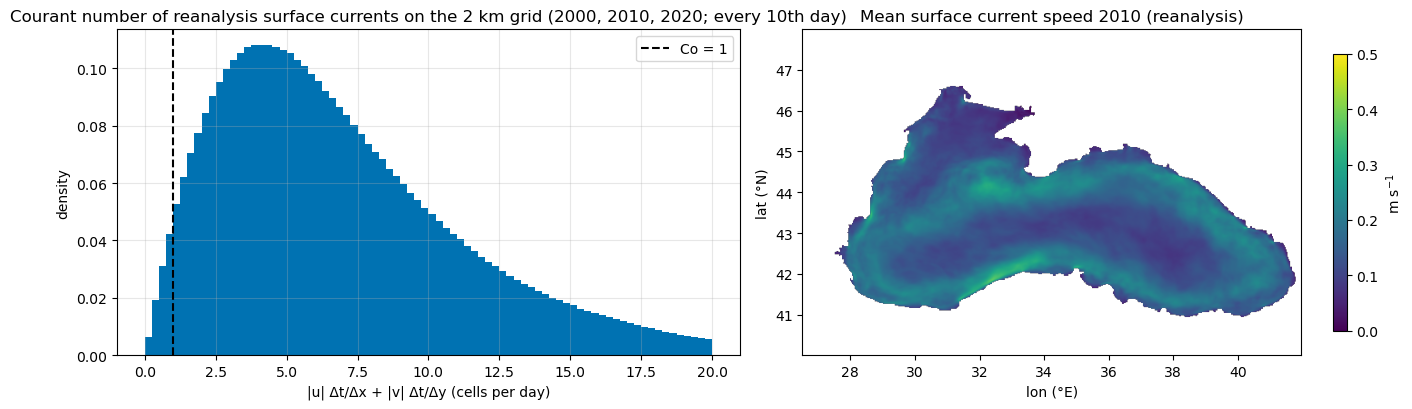

In [6]:
dx, dy, _, _ = grid_metrics(lat.astype(float), lon.astype(float))
rows = []
co_all = []
for y in [2000, 2010, 2020]:
    s = d.sel(time=str(y))
    c = np.log(s.chl_l3.values)
    ok = np.isfinite(c) & ocean
    both = ok[1:] & ok[:-1]
    dch = np.abs(c[1:] - c[:-1])[both]
    u = s.uo.isel(time=slice(0, None, 10)).values
    v = s.vo.isel(time=slice(0, None, 10)).values
    co = np.abs(u) * 86400 / np.abs(dx) + np.abs(v) * 86400 / np.abs(dy)
    co = co[:, ocean]
    co = co[np.isfinite(co)]
    co_all.append(co)
    rows.append(
        (
            y,
            int(both.sum()),
            np.mean(dch),
            np.median(dch),
            np.percentile(dch, 90),
            np.median(co),
            np.mean(co > 1),
            np.mean(co > 5),
        )
    )
print(
    f"{'year':>5} {'px pairs':>10} {'mean|Δ|':>8} {'median':>7} {'p90':>6} {'Co median':>10} {'Co>1':>6} {'Co>5':>6}"
)
for r in rows:
    print(
        f"{r[0]:5d} {r[1]:10,d} {r[2]:8.3f} {r[3]:7.3f} {r[4]:6.3f} {r[5]:10.2f} {r[6]:6.2f} {r[7]:6.2f}"
    )
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(
    np.concatenate(co_all),
    bins=np.linspace(0, 20, 81),
    color=OKABE_ITO[0],
    density=True,
)
ax[0].axvline(1, color="k", ls="--", label="Co = 1")
ax[0].set(
    title="Courant number of reanalysis surface currents on the 2 km grid (2000, 2010, 2020; every 10th day)",
    xlabel="|u| Δt/Δx + |v| Δt/Δy (cells per day)",
    ylabel="density",
)
ax[0].legend()
ax[0].grid(alpha=0.3)
spd = np.hypot(
    d.uo.sel(time="2010").isel(time=slice(0, None, 10)).values,
    d.vo.sel(time="2010").isel(time=slice(0, None, 10)).values,
).mean(0)
spd[~ocean] = np.nan
im = ax[1].imshow(
    spd, extent=ext, origin="lower", cmap="viridis", vmin=0, vmax=0.5, aspect="auto"
)
ax[1].set(
    title="Mean surface current speed 2010 (reanalysis)",
    xlabel="lon (°E)",
    ylabel="lat (°N)",
)
fig.colorbar(im, ax=ax[1], label="m s$^{-1}$", shrink=0.85)
fig.tight_layout()
plt.show()

## 6. Real-cloud cover vs the physics fields (within-day)

Same check as for the Indian Ocean: standardised difference of each field between cloudy and observed pixels within a day, averaged over days.

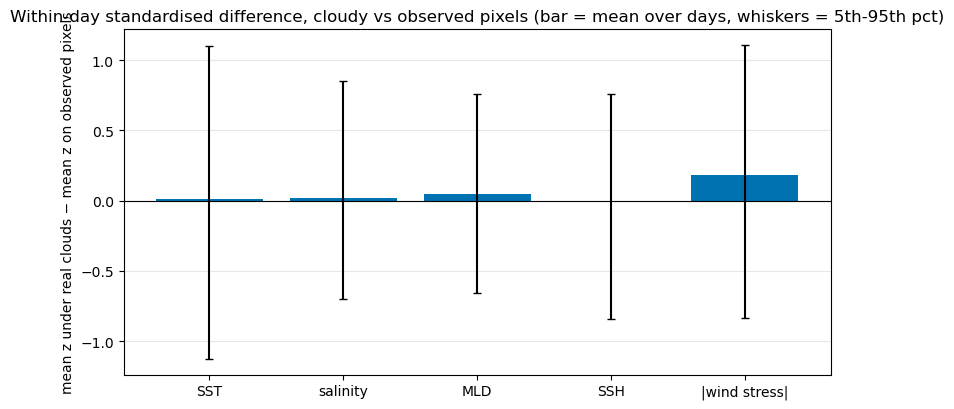

thetao   mean +0.015   days>0 0.53   n days 464
so       mean +0.018   days>0 0.51   n days 464
mlotst   mean +0.046   days>0 0.53   n days 464
zos      mean -0.003   days>0 0.51   n days 464
tau      mean +0.186   days>0 0.60   n days 464


In [7]:
feats = {"thetao": d.thetao, "so": d.so, "mlotst": d.mlotst, "zos": d.zos, "tau": None}
out = {}
for nm, da in feats.items():
    x = (
        np.hypot(d.tauuo.isel(time=sub).values, d.tauvo.isel(time=sub).values)
        if nm == "tau"
        else da.isel(time=sub).values
    )
    vals = []
    for i in range(0, len(ts), 2):
        xi = x[i]
        ok = np.isfinite(xi) & ocean
        c, o = cloud[i] & ok, obs[i] & ok
        if c.sum() < 500 or o.sum() < 500:
            continue
        mu, sd = xi[ok].mean(), xi[ok].std() + 1e-6
        vals.append((xi[c].mean() - xi[o].mean()) / sd)
    out[nm] = np.array(vals); del x
fig, ax = plt.subplots(figsize=(8, 4.2))
xi_ = np.arange(len(out))
mean = [v.mean() for v in out.values()]
ax.bar(xi_, mean, color=OKABE_ITO[0])
ax.errorbar(
    xi_,
    mean,
    yerr=[
        [m_ - np.percentile(v, 5) for m_, v in zip(mean, out.values())],
        [np.percentile(v, 95) - m_ for m_, v in zip(mean, out.values())],
    ],
    fmt="none",
    ecolor="k",
    capsize=3,
)
ax.axhline(0, color="k", lw=0.8)
ax.set(
    xticks=xi_,
    xticklabels=["SST", "salinity", "MLD", "SSH", "|wind stress|"],
    ylabel="mean z under real clouds − mean z on observed pixels",
    title="Within-day standardised difference, cloudy vs observed pixels (bar = mean over days, whiskers = 5th-95th pct)",
)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()
for nm, v in out.items():
    print(
        f"{nm:8s} mean {v.mean():+.3f}   days>0 {np.mean(v > 0):.2f}   n days {len(v)}"
    )

## 7. Quality index and pixel count per 2 km block

`qi_chl` is the product's per-pixel quality index (block mean); `chl_l3_n` the number of valid 1 km pixels in each 2×2 block (0-4).

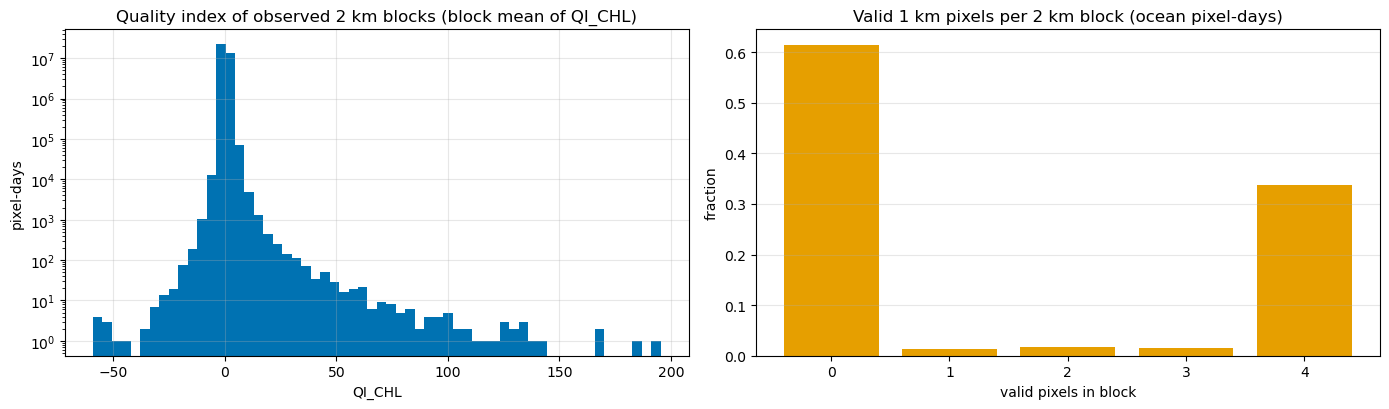

blocks with 1-3 valid pixels are partially cloudy at 1 km: 12.4% of observed blocks


In [8]:
qi = d.qi_chl.isel(time=sub).values
n3 = d.chl_l3_n.isel(time=sub).values
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(qi[obs & np.isfinite(qi)], bins=60, color=OKABE_ITO[0])
ax[0].set(
    title="Quality index of observed 2 km blocks (block mean of QI_CHL)",
    xlabel="QI_CHL",
    ylabel="pixel-days",
    yscale="log",
)
ax[0].grid(alpha=0.3)
cnt = np.bincount(n3[ocean[None].repeat(len(ts), 0)].astype(int), minlength=5)
ax[1].bar(range(5), cnt / cnt.sum(), color=OKABE_ITO[1])
ax[1].set(
    title="Valid 1 km pixels per 2 km block (ocean pixel-days)",
    xlabel="valid pixels in block",
    ylabel="fraction",
)
ax[1].grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()
print(
    "blocks with 1-3 valid pixels are partially cloudy at 1 km:",
    f"{cnt[1:4].sum() / cnt[1:].sum():.1%} of observed blocks",
)

## 8. Notes for modelling

* Observed fraction is 23-49 % of ocean pixel-days by year, rising over the record as sensors were added, with a strong seasonal cycle; the training/validation split should again interleave years.
* The reanalysis physics is missing on ~15 % of CHL ocean pixels (Azov, Marmara, parts of the coast); either mask those out of the CHL domain or feed NaN → 0 plus a flag as in the Indian Ocean runs.
* The Courant number of the currents on the 2 km grid is far above 1 almost everywhere, so a daily finite-difference transport residual is not usable at this resolution; a semi-Lagrangian (back-trajectory) formulation is required if the transport term is kept.
* L4 under real clouds sits below the clear-sky climatology; that bias and the L4's own smoothing are why the L4 is a reference row, not the truth, in any hidden-pixel protocol here.